<font size=7 color="#5499C7" >Assignment 2: OCR</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

In [1]:
import os
import random
import string
import numpy as np
import pandas as pd
from scipy import ndimage
import matplotlib.pyplot as plt
from scipy.ndimage import label, find_objects
from PIL import ImageFilter, ImageFont, ImageDraw, Image

OUT_DIR = "Captcha"
mapset_dir = "Mapset"
os.makedirs(OUT_DIR, exist_ok=True)

WIDTH, HEIGHT = 200, 100
N_SAMPLES = 10
CHARS = string.ascii_lowercase + string.digits
FONT_SIZE = 40

font = ImageFont.truetype("arial.ttf", FONT_SIZE)

<font size=7 color="#5499C7" >Part 1: Generating Data</font>

<p align="justify"><font size="6" color="#A9CCE3"><b>Sample Generation</b></font><br></p>

<p align="justify">
Here we generated 10 random samples each containing 3 characters
</p>

In [2]:
def generate_captcha(text):    
    img = Image.new("RGB", (WIDTH, HEIGHT), (255, 255, 255))
    draw = ImageDraw.Draw(img)
    
    bbox = draw.textbbox((0, 0), text, font=font)
    text_w = bbox[2] - bbox[0]
    text_h = bbox[3] - bbox[1]
    x = (WIDTH - text_w) // 2
    y = (HEIGHT - text_h) // 2
    
    draw.text((x, y), text, font=font, fill=(0, 0, 0))

    text_mask = Image.new("L", (WIDTH, HEIGHT), 255)  
    mask_draw = ImageDraw.Draw(text_mask)
    mask_draw.text((x, y), text, font=font, fill=0)

    return img

In [3]:
for i in range(N_SAMPLES):
    text = ''.join(random.choices(CHARS, k=3))
    img = generate_captcha(text)
    img.save(os.path.join(OUT_DIR, f"{text}_{i:02d}.png"))

print(f"{N_SAMPLES} samples '{OUT_DIR}'")

10 samples 'Captcha'


<p align="justify"><font size="6" color="#A9CCE3"><b>Salt and Pepper Noise</b></font><br></p>

<p align="justify">
Here we added salt and pepper noise to the samples generated and plotted them after the noise
</p>

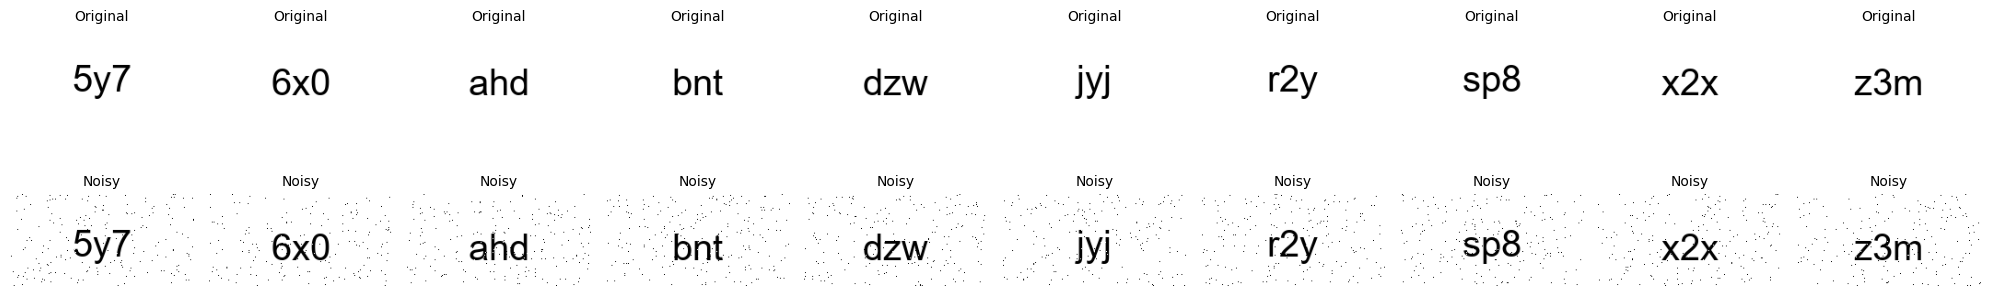

In [4]:
def add_salt_pepper_noise(image, salt_prob=0.01, pepper_prob=0.01):
    img_array = np.array(image)
    noisy_img = img_array.copy()
    
    # Salt noise (white pixels)
    salt_mask = np.random.random(img_array.shape[:2]) < salt_prob
    noisy_img[salt_mask] = [255, 255, 255] 
    
    # Pepper noise (black pixels)
    pepper_mask = np.random.random(img_array.shape[:2]) < pepper_prob
    noisy_img[pepper_mask] = [0, 0, 0]
    
    return Image.fromarray(noisy_img)

files = sorted([f for f in os.listdir(OUT_DIR) if f.endswith('.png') and not f.startswith('noisy_')])

original_images = []
noisy_images = []

for filename in files:
    original_path = os.path.join(OUT_DIR, filename)
    original_img = Image.open(original_path)
    original_images.append(original_img)
    
    noisy_img = add_salt_pepper_noise(original_img)
    noisy_images.append(noisy_img)

    noisy_filename = f"noisy_{filename}"
    noisy_img.save(os.path.join(OUT_DIR, noisy_filename))

fig, axes = plt.subplots(2, len(original_images), figsize=(20, 4))

for i in range(len(original_images)):
    axes[0, i].imshow(original_images[i])
    axes[0, i].set_title("Original", fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(noisy_images[i])
    axes[1, i].set_title("Noisy", fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

<p align="justify"><font size="6" color="#A9CCE3"><b>Blurring</b></font><br></p>

<p align="justify low">
Here we blurred the images using a 5x5 Gaussian blur kernel because it provides a smooth, natural-looking blur that simulates optical blur, with its values following a Gaussian distribution where the center pixel has the highest weight and the influence decreases smoothly for surrounding pixels; this symmetric kernel ensures uniform blurring in all directions, its normalized values that sum to 1 preserve the image's overall brightness, and the 5x5 size offers a moderate, noticeable-but-not-excessive blurring strength, making it a standard and widely used choice for image preprocessing and augmentation.
</p>

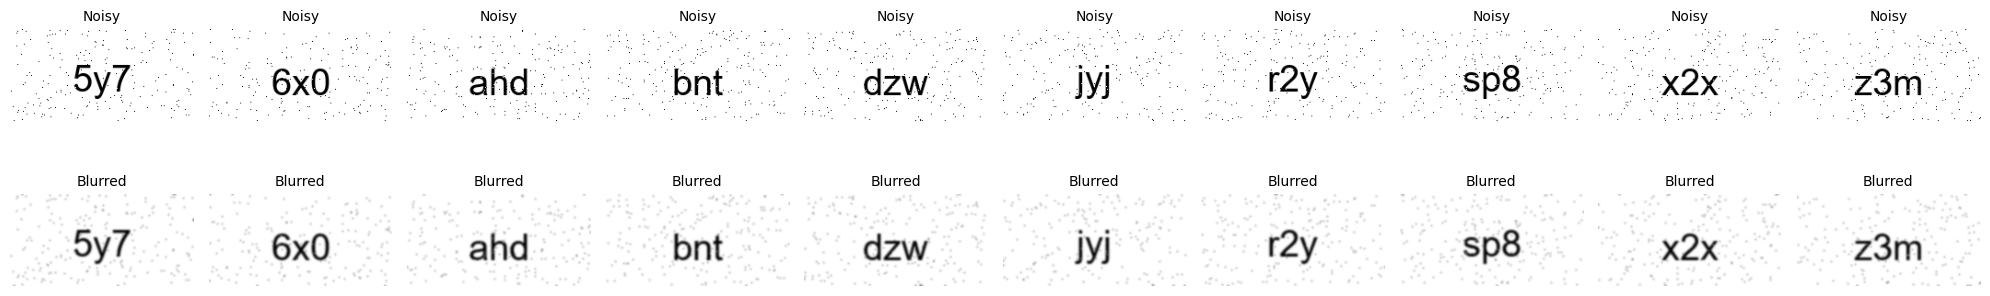

In [5]:
# Define a Gaussian blur kernel (5x5)
kernel = np.array([
    [1, 4, 7, 4, 1],
    [4, 16, 26, 16, 4],
    [7, 26, 41, 26, 7],
    [4, 16, 26, 16, 4],
    [1, 4, 7, 4, 1],
]) / 273  # Normalize so sum equals 1

def apply_kernel_blur(image, kernel):
    img_array = np.array(image)
    blurred_channels = []
    for i in range(img_array.shape[2]):  # For each RGB channel
        channel = img_array[:, :, i]
        blurred_channel = ndimage.convolve(channel, kernel)
        blurred_channels.append(blurred_channel)
    
    # Stack the blurred channels back together
    blurred_img_array = np.stack(blurred_channels, axis=2)
    return Image.fromarray(blurred_img_array.astype('uint8'))

noisy_files = sorted([f for f in os.listdir(OUT_DIR) if f.startswith('noisy_') and f.endswith('.png')])
noisy_images = []
blurred_images = []

for filename in noisy_files:
    noisy_path = os.path.join(OUT_DIR, filename)
    noisy_img = Image.open(noisy_path)
    noisy_images.append(noisy_img)
    
    blurred_img = apply_kernel_blur(noisy_img, kernel)
    blurred_images.append(blurred_img)

    blurred_filename = f"blurred_{filename}"
    blurred_img.save(os.path.join(OUT_DIR, blurred_filename))

fig, axes = plt.subplots(2, len(noisy_images), figsize=(20, 4))

for i in range(len(noisy_images)):
    axes[0, i].imshow(noisy_images[i])
    axes[0, i].set_title("Noisy", fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(blurred_images[i])
    axes[1, i].set_title("Blurred", fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

<font size=7 color="#5499C7" >Part 2: Preprocessing Data</font>

<p align="justify"><font size="6" color="#A9CCE3"><b>Denoising</b></font><br></p>

<p align="justify low">
Here we tried to remove the noise we added to our images before using a blurring filter
Blurring filters are effective at removing noise from images because they work by averaging pixel values with their neighboring pixels, which helps to smooth out random variations caused by noise. When noise appears as isolated bright or dark pixels (like salt and pepper noise), applying a blur filter distributes these outlier values across the surrounding area, effectively reducing their impact and creating a more uniform appearance. The averaging process essentially acts as a low-pass filter that preserves the overall structure and important features of the image while attenuating the high-frequency components associated with noise. For optimal noise removal, we used a 7x7 Gaussian kernel which provides stronger blurring effect due to its larger size and more extensive neighborhood averaging
</p>

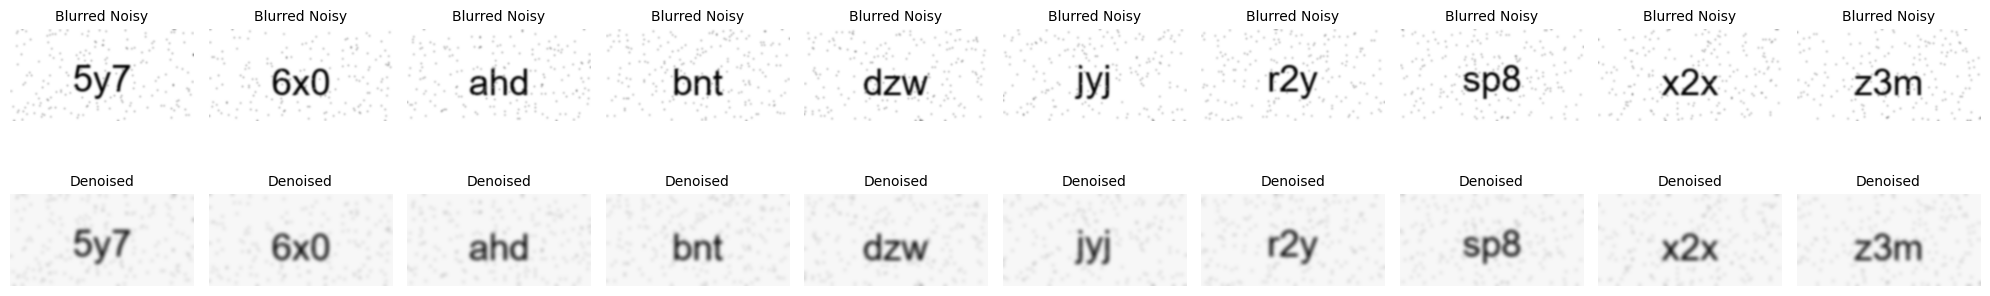

In [6]:
# Define a 7x7 Gaussian blur kernel for stronger noise reduction
kernel = np.array([
    [1,  1,  2,  2,  2,  1,  1],
    [1,  2,  3,  4,  3,  2,  1],
    [2,  3,  5,  6,  5,  3,  2],
    [2,  4,  6,  8,  6,  4,  2],
    [2,  3,  5,  6,  5,  3,  2],
    [1,  2,  3,  4,  3,  2,  1],
    [1,  1,  2,  2,  2,  1,  1]
]) / 140  # Normalize so sum equals 1

# Load blurred_noisy images and create denoised versions
blurred_files = sorted([f for f in os.listdir(OUT_DIR) if f.startswith('blurred_noisy') and f.endswith('.png')])
blurred_images = []
denoised_images = []

for filename in blurred_files:
    blurred_path = os.path.join(OUT_DIR, filename)
    blurred_img = Image.open(blurred_path)
    blurred_images.append(blurred_img)
    
    denoised_img = apply_kernel_blur(blurred_img, kernel)
    denoised_images.append(denoised_img)

    denoised_filename = f"denoised_{filename}"
    denoised_img.save(os.path.join(OUT_DIR, denoised_filename))

fig, axes = plt.subplots(2, len(blurred_images), figsize=(20, 4))

for i in range(len(blurred_images)):
    axes[0, i].imshow(blurred_images[i])
    axes[0, i].set_title("Blurred Noisy", fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(denoised_images[i])
    axes[1, i].set_title("Denoised", fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

<p align="justify"><font size="6" color="#A9CCE3"><b>Sharpening and De-blurring</b></font><br></p>

<p align="justify low">
Sharpening and de-blurring are image enhancement techniques used to improve the clarity and definition of images. Sharpening works by enhancing the edges and fine details in an image, typically using kernels that emphasize high-frequency components, while de-blurring specifically aims to reverse the effects of blur by attempting to recover the original sharp image from a blurred version using inverse filtering or other restoration algorithms. For denoised_blurred_noisy images, we applied a sharpening filter using a 3x3 kernel that enhances edges and details, which will help counteract the blurring effect and make the text more distinct
</p>

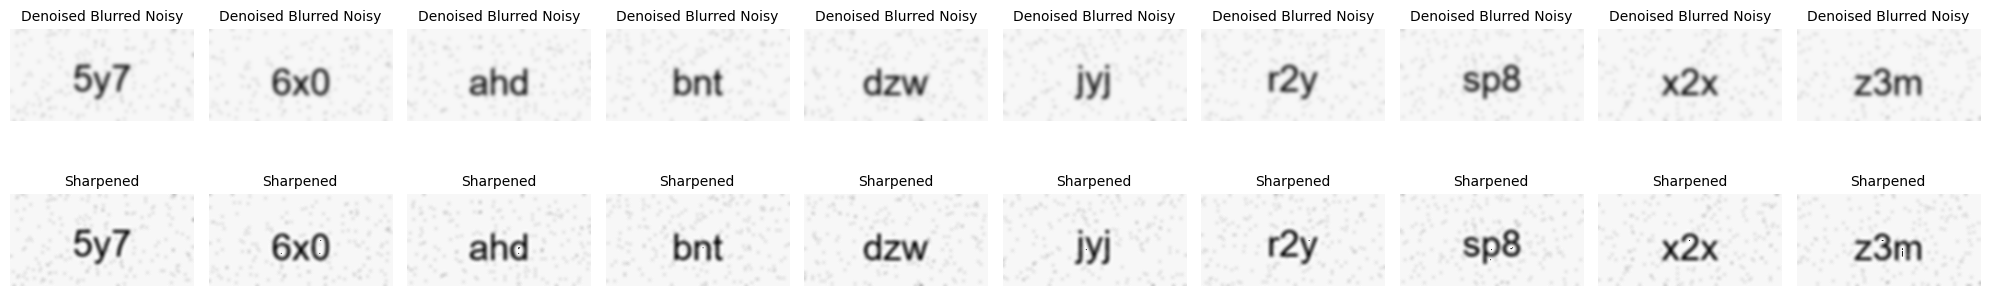

In [7]:
# Define a sharpening kernel
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

def apply_sharpening(image, kernel):
    img_array = np.array(image)
    sharpened_channels = []
    for i in range(img_array.shape[2]):  # For each RGB channel
        channel = img_array[:, :, i]
        sharpened_channel = ndimage.convolve(channel, kernel)
        # Clip values to valid range [0, 255]
        sharpened_channel = np.clip(sharpened_channel, 0, 255)
        sharpened_channels.append(sharpened_channel)

    sharpened_img_array = np.stack(sharpened_channels, axis=2)
    return Image.fromarray(sharpened_img_array.astype('uint8'))

denoised_files = sorted([f for f in os.listdir(OUT_DIR) if f.startswith('denoised_blurred_noisy') and f.endswith('.png')])
denoised_images = []
sharpened_images = []

for filename in denoised_files:
    denoised_path = os.path.join(OUT_DIR, filename)
    denoised_img = Image.open(denoised_path)
    denoised_images.append(denoised_img)
    
    sharpened_img = apply_sharpening(denoised_img, sharpen_kernel)
    sharpened_images.append(sharpened_img)

    sharpened_filename = f"sharpened_{filename}"
    sharpened_img.save(os.path.join(OUT_DIR, sharpened_filename))

fig, axes = plt.subplots(2, len(denoised_images), figsize=(20, 4))

for i in range(len(denoised_images)):
    axes[0, i].imshow(denoised_images[i])
    axes[0, i].set_title("Denoised Blurred Noisy", fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(sharpened_images[i])
    axes[1, i].set_title("Sharpened", fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

<p align="justify"><font size="6" color="#A9CCE3"><b>Another Denoising method</b></font><br></p>

<p align="justify">
Here we changed the iamages to be binary and removed those components less than threshold
</p>

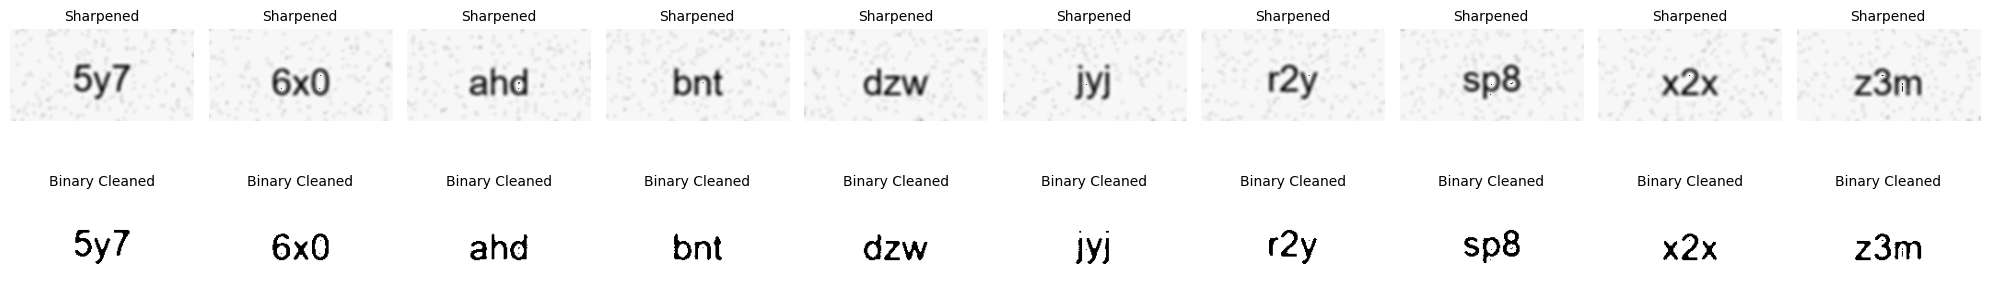

In [8]:
def convert_to_binary_and_remove_small_components(image, threshold=128, min_size=50):
    gray_img = image.convert('L')
    img_array = np.array(gray_img)
    
    # Create binary image
    binary_img = (img_array > threshold).astype(int)
    
    # Label connected components
    labeled_array, num_features = ndimage.label(binary_img)
    
    # Calculate sizes of each component
    component_sizes = ndimage.sum(binary_img, labeled_array, range(num_features + 1))
    
    # Create mask for components larger than threshold
    mask_size = component_sizes > min_size
    mask = mask_size[labeled_array]
    
    # Apply mask to keep only large components
    cleaned_binary = binary_img * mask

    cleaned_binary_img = (cleaned_binary * 255).astype('uint8')
    
    return Image.fromarray(cleaned_binary_img, mode='L')

sharpened_files = sorted([f for f in os.listdir(OUT_DIR) if f.startswith('sharpened_denoised_blurred_noisy') and f.endswith('.png')])
sharpened_images = []
binary_images = []

for filename in sharpened_files:
    sharpened_path = os.path.join(OUT_DIR, filename)
    sharpened_img = Image.open(sharpened_path)
    sharpened_images.append(sharpened_img)
    
    binary_img = convert_to_binary_and_remove_small_components(sharpened_img, threshold=128, min_size=30)
    binary_images.append(binary_img)

    binary_filename = f"binary_{filename}"
    binary_img.save(os.path.join(OUT_DIR, binary_filename))

fig, axes = plt.subplots(2, len(sharpened_images), figsize=(20, 4))

for i in range(len(sharpened_images)):
    axes[0, i].imshow(sharpened_images[i])
    axes[0, i].set_title("Sharpened", fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(binary_images[i], cmap='gray')
    axes[1, i].set_title("Binary Cleaned", fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

<font size=7 color="#5499C7" >Part 3: Segmentation</font>

<p align="justify low">
Here we extracted characters from images of the previous section and reported the number of them
</p>

In [9]:
def extract_characters(binary_image, min_width=5, min_height=10):
    img_array = np.array(binary_image)
    
    # Find connected components
    labeled_array, num_features = label(img_array == 0)  # Assuming text is black (0)
    
    # Get bounding boxes for each component
    slices = find_objects(labeled_array)
    
    characters = []
    for i, slice_tuple in enumerate(slices):
        if slice_tuple is not None:
            char_region = img_array[slice_tuple]
            height, width = char_region.shape
            
            # Filter by minimum size to avoid noise
            if width >= min_width and height >= min_height:
                # Extract character with some padding
                char_img = Image.fromarray(char_region, mode='L')
                characters.append(char_img)
    
    return characters

def resize_to_64x64(image):
    return image.resize((64, 64), Image.Resampling.LANCZOS)

char_output_dir = os.path.join(OUT_DIR, "segmented_chars")
os.makedirs(char_output_dir, exist_ok=True)

binary_files = sorted([f for f in os.listdir(OUT_DIR) if f.startswith('binary_sharpened_denoised_blurred_noisy') and f.endswith('.png')])
all_characters = []

for idx, filename in enumerate(binary_files):
    binary_path = os.path.join(OUT_DIR, filename)
    binary_img = Image.open(binary_path)
    
    characters = extract_characters(binary_img)
    print(f"Image {filename}: {len(characters)} characters extracted")

    for char_idx, char_img in enumerate(characters):
        resized_char = resize_to_64x64(char_img)
        
        # Create a unique filename based on the original image and character index
        base_name = os.path.splitext(filename)[0]
        char_filename = f"{base_name}_char_{char_idx}.png"
        char_path = os.path.join(char_output_dir, char_filename)
        
        resized_char.save(char_path)
        all_characters.append(resized_char)

print(f"\nTotal characters saved: {len(all_characters)}")
print(f"Characters saved in folder: {char_output_dir}")

Image binary_sharpened_denoised_blurred_noisy_5y7_04.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_6x0_05.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_ahd_01.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_bnt_03.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_dzw_08.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_jyj_07.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_r2y_02.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_sp8_06.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_x2x_09.png: 3 characters extracted
Image binary_sharpened_denoised_blurred_noisy_z3m_00.png: 3 characters extracted

Total characters saved: 30
Characters saved in folder: Captcha\segmented_chars


<font size=7 color="#5499C7" >Part 4: Character Recognition</font>

<p align="justify low">
We evaluated the similarity between our segmented CAPTCHA characters (from segmented_chars folder) and template images in the Mapset folder using Normalized Cross-Correlation — a non-learning, structural matching method. For each segmented character, it compares it against all templates, finds the best match based on correlation score, and saves the results to a CSV file with three columns: the segmented image filename, its predicted label (the best-matching template), and the correlation score. This allows you to assess recognition accuracy without machine learning.
</p>

In [10]:
def calculate_normalized_cross_correlation(img1, img2):
    # Convert to numpy arrays and normalize
    arr1 = np.array(img1).astype(np.float32)
    arr2 = np.array(img2).astype(np.float32)
    
    # Normalize images
    arr1 = (arr1 - np.mean(arr1)) / (np.std(arr1) + 1e-8)
    arr2 = (arr2 - np.mean(arr2)) / (np.std(arr2) + 1e-8)
    
    # Calculate correlation
    correlation = np.sum(arr1 * arr2) / (np.sqrt(np.sum(arr1**2) * np.sum(arr2**2)) + 1e-8)
    return correlation

def load_mapset_images(mapset_dir):
    templates = {}
    for filename in os.listdir(mapset_dir):
        if filename.endswith('.png'):
            label = os.path.splitext(filename)[0]
            img_path = os.path.join(mapset_dir, filename)
            img = Image.open(img_path).convert('L')  # Convert to grayscale
            
            # INVERT MAPSET IMAGES to match segmented images (black text on white bg)
            img = Image.fromarray(255 - np.array(img))
            
            templates[label] = img
    return templates

def evaluate_similarity(segmented_dir, mapset_dir, output_csv_path):
    templates = load_mapset_images(mapset_dir)
    
    # Get list of segmented character files
    segmented_files = sorted([f for f in os.listdir(segmented_dir) if f.endswith('.png')])
    
    results = []
    
    for segment_file in segmented_files:
        segment_path = os.path.join(segmented_dir, segment_file)
        segment_img = Image.open(segment_path).convert('L')
        
        best_match_label = None
        best_correlation = -1.0

        for label, template_img in templates.items():
            if segment_img.size != template_img.size:
                template_img = template_img.resize(segment_img.size, Image.Resampling.LANCZOS)
            
            correlation = calculate_normalized_cross_correlation(segment_img, template_img)
            
            if correlation > best_correlation:
                best_correlation = correlation
                best_match_label = label
        
        results.append({
            'segment_file': segment_file,
            'predicted_label': best_match_label,
            'correlation': best_correlation
        })

    df = pd.DataFrame(results)
    df.to_csv(output_csv_path, index=False)
    
    print(f"Similarity evaluation completed. Results saved to {output_csv_path}")
    print(f"Total segments evaluated: {len(results)}")
    
    return df

segmented_dir = os.path.join(OUT_DIR, "segmented_chars")
output_csv_path = os.path.join(OUT_DIR, "character_recognition_results.csv")

results_df = evaluate_similarity(segmented_dir, mapset_dir, output_csv_path)

print("\nFirst 5 results:")
print(results_df.head())

Similarity evaluation completed. Results saved to Captcha\character_recognition_results.csv
Total segments evaluated: 30

First 5 results:
                                        segment_file predicted_label  \
0  binary_sharpened_denoised_blurred_noisy_5y7_04...               5   
1  binary_sharpened_denoised_blurred_noisy_5y7_04...               7   
2  binary_sharpened_denoised_blurred_noisy_5y7_04...               y   
3  binary_sharpened_denoised_blurred_noisy_6x0_05...               6   
4  binary_sharpened_denoised_blurred_noisy_6x0_05...               0   

   correlation  
0     0.527225  
1     0.768282  
2     0.684864  
3     0.645541  
4     0.658002  
